In [1]:
#Import libraries and load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("hospital_cleaned.csv")

# Display the first five records
display(df.head())

# Check dataset size
print("Dataset shape:", df.shape)

# View column names and data types
df.info()


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


Dataset shape: (55500, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), o

In [2]:
#Clean and preprocess the data
# Check missing values
print(df.isnull().sum())

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Clean column names
df.columns = df.columns.str.strip()

# Convert date columns if they exist
for col in ["Date of Admission", "Discharge Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Show updated dataset information
print("Cleaned dataset shape:", df.shape)
display(df.head())


Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64
Duplicate rows: 534
Cleaned dataset shape: (54966, 15)


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [3]:
#Perform exploratory data analysis (EDA)
# Summary statistics
display(df.describe(include="all").T)

# Most common medical conditions
if "Medical Condition" in df.columns:
    print(df["Medical Condition"].value_counts())

# Patient age distribution
if "Age" in df.columns:
    print("Average age:", round(df["Age"].mean(), 2))
    print("Median age:", df["Age"].median())

# Average billing amount
if "Billing Amount" in df.columns:
    print("Average billing:",
          round(df["Billing Amount"].mean(), 2))


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Name,54966,49992,DAvId muNoZ,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,54966.0,NaN,NaN,NaN,51.535185,13.0,35.0,52.0,68.0,89.0,19.605661
Gender,54966,2,Male,27496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Type,54966,8,A-,6898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medical Condition,54966,6,Arthritis,9218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Admission,54966,NaN,NaN,NaN,2021-11-01 17:35:29.505512448,2019-05-08 00:00:00,2020-07-28 00:00:00,2021-11-02 00:00:00,2023-02-03 00:00:00,2024-05-07 00:00:00,NaN
Doctor,54966,40341,Michael Smith,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hospital,54966,39876,LLC Smith,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Insurance Provider,54966,5,Cigna,11139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Billing Amount,54966.0,NaN,NaN,NaN,25544.306284,-2008.49214,13243.718641,25542.749145,37819.858159,52764.276736,14208.409711


Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64
Average age: 51.54
Median age: 52.0
Average billing: 25544.31


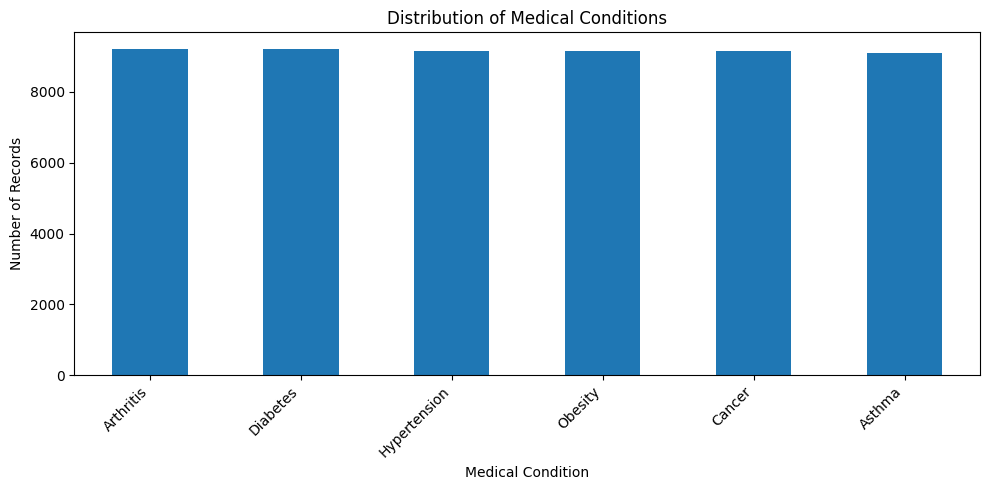

In [4]:
#Create visualizations
# Chart 1: Distribution of medical conditions
if "Medical Condition" in df.columns:
    counts = df["Medical Condition"].value_counts()

    counts.plot(kind="bar", figsize=(10, 5))
    plt.title("Distribution of Medical Conditions")
    plt.xlabel("Medical Condition")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


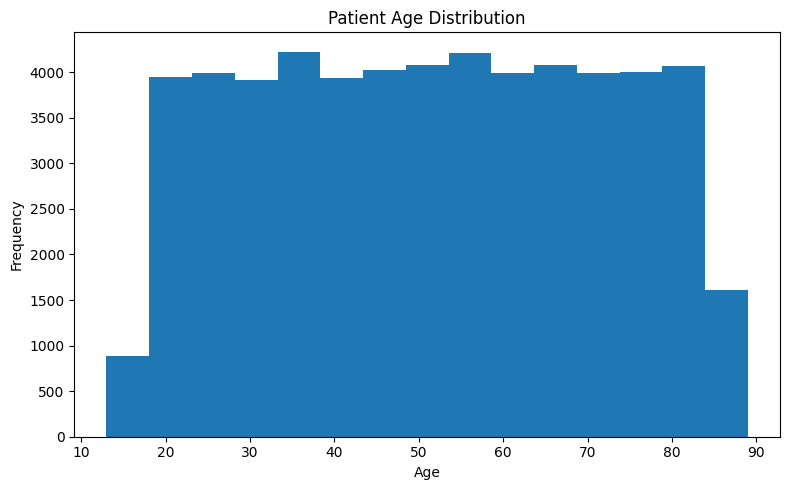

In [6]:
#Create a histogram for patient age:
if "Age" in df.columns:
    df["Age"].plot(
        kind="hist", bins=15, figsize=(8, 5)
    )
    plt.title("Patient Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


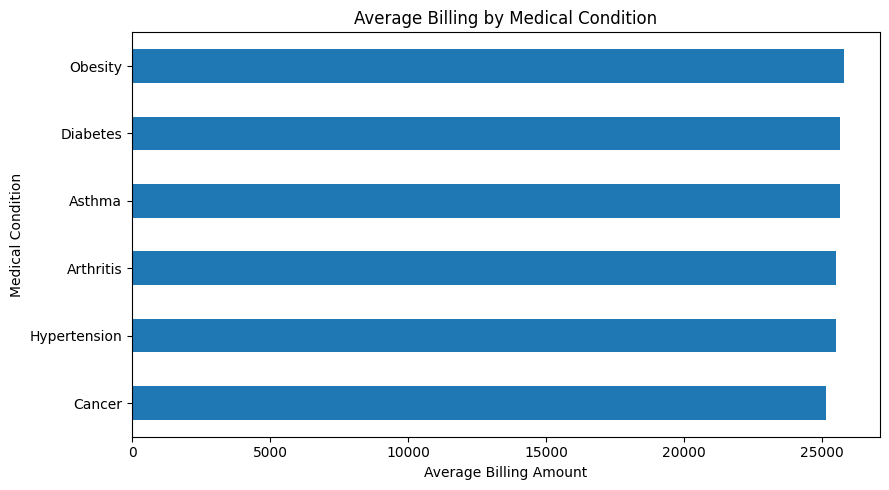

In [7]:
#Compare average billing by medical condition:

if {"Medical Condition", "Billing Amount"}.issubset(df.columns):
    billing = df.groupby(
        "Medical Condition"
    )["Billing Amount"].mean().sort_values()

    billing.plot(kind="barh", figsize=(9, 5))
    plt.title("Average Billing by Medical Condition")
    plt.xlabel("Average Billing Amount")
    plt.ylabel("Medical Condition")
    plt.tight_layout()
    plt.show()


Generate useful findings
After creating the charts, write a short interpretation for each one. For example:
- The most frequently recorded medical condition was [insert the condition found in your results].
- The largest patient age group was [insert the age range supported by your histogram].
- The medical condition with the highest average billing was [insert your calculated result].
These are examples of how to report results, not actual findings from the dataset.

Remember: billing differences or condition frequencies do not establish that a treatment is effective or that one group has worse health outcomes.

In [8]:
#Save your analysis results

# Save cleaned data
df.to_csv("healthcare_cleaned.csv", index=False)

# Save average billing by condition
if {"Medical Condition", "Billing Amount"}.issubset(df.columns):
    summary = (
        df.groupby("Medical Condition")["Billing Amount"]
        .agg(["count", "mean", "median"])
        .round(2)
    )

    summary.to_csv("healthcare_summary.csv")
    display(summary)

print("Analysis outputs saved.")


,count,mean,median
Medical Condition,,,
Arthritis,9218,25511.78,25599.18
Asthma,9095,25633.46,25628.41
Cancer,9140,25152.32,24910.71
Diabetes,9216,25660.48,25647.71
Hypertension,9151,25503.06,25281.63
Obesity,9146,25804.36,26145.58


Analysis outputs saved.


In [10]:
#Verify your project outputs

import os

files_to_check = [
    "/content/healthcare_cleaned.csv",
    "/content/healthcare_summary.csv",
    "/content/hospital_cleaned.csv"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"FOUND: {file} ({os.path.getsize(file):,} bytes)")
    else:
        print(f"NOT FOUND: {file}")


FOUND: /content/healthcare_cleaned.csv (8,257,189 bytes)
FOUND: /content/healthcare_summary.csv (228 bytes)
FOUND: /content/hospital_cleaned.csv (8,399,221 bytes)


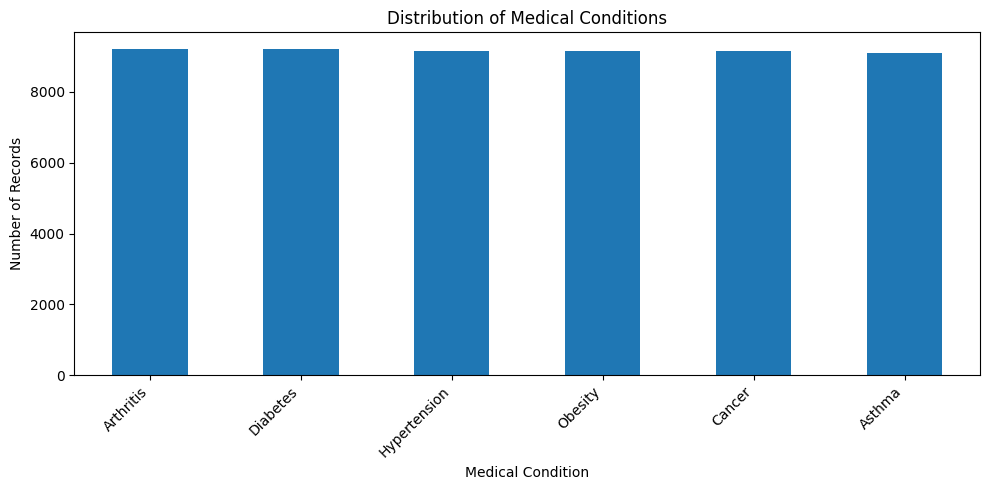

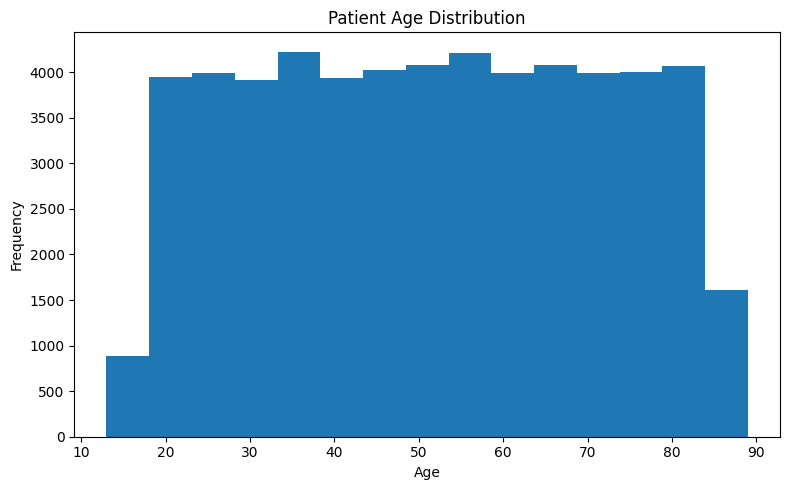

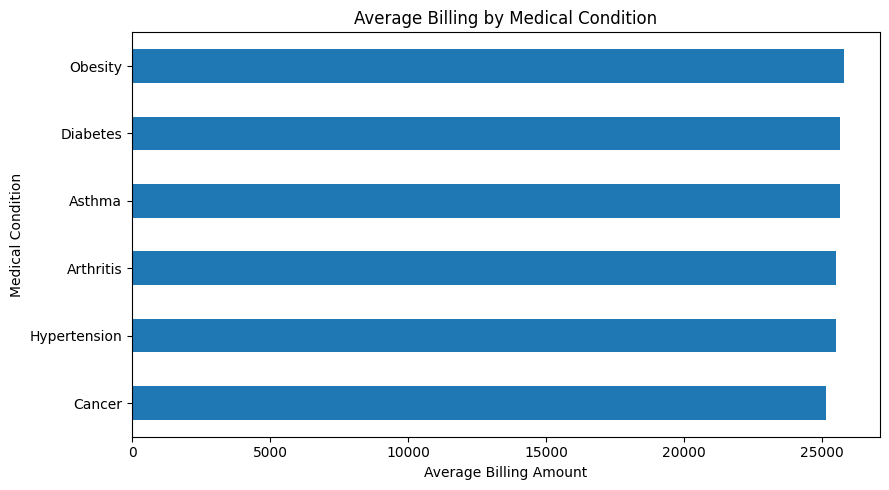

In [11]:
#Save your charts separately

import os
import matplotlib.pyplot as plt

os.makedirs("visualizations", exist_ok=True)

# Medical condition distribution
if "Medical Condition" in df.columns:
    df["Medical Condition"].value_counts().plot(
        kind="bar", figsize=(10, 5)
    )
    plt.title("Distribution of Medical Conditions")
    plt.xlabel("Medical Condition")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(
        "visualizations/medical_conditions.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Age distribution
if "Age" in df.columns:
    df["Age"].plot(kind="hist", bins=15, figsize=(8, 5))
    plt.title("Patient Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(
        "visualizations/age_distribution.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Average billing by medical condition
if {"Medical Condition", "Billing Amount"}.issubset(df.columns):
    billing = df.groupby(
        "Medical Condition"
    )["Billing Amount"].mean().sort_values()

    billing.plot(kind="barh", figsize=(9, 5))
    plt.title("Average Billing by Medical Condition")
    plt.xlabel("Average Billing Amount")
    plt.tight_layout()
    plt.savefig(
        "visualizations/average_billing.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()
    plt.close()


In [12]:
#Generate actual findings from your data

# Healthcare analytics findings
print("HEALTHCARE DATA ANALYTICS — KEY FINDINGS")
print("=" * 45)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

if "Age" in df.columns:
    ages = pd.to_numeric(df["Age"], errors="coerce").dropna()
    if not ages.empty:
        print(f"Average patient age: {ages.mean():.2f}")
        print(f"Median patient age: {ages.median():.2f}")

if "Medical Condition" in df.columns:
    conditions = df["Medical Condition"].dropna().value_counts()
    if not conditions.empty:
        print("Most frequent medical condition:", conditions.index[0])
        print("Number of records:", conditions.iloc[0])

if {"Medical Condition", "Billing Amount"}.issubset(df.columns):
    billing_df = df.copy()
    billing_df["Billing Amount"] = pd.to_numeric(
        billing_df["Billing Amount"], errors="coerce"
    )
    billing = billing_df.groupby(
        "Medical Condition"
    )["Billing Amount"].mean().dropna()

    if not billing.empty:
        print("Highest average billing condition:", billing.idxmax())
        print(f"Average billing: {billing.max():.2f}")

print("=" * 45)


HEALTHCARE DATA ANALYTICS — KEY FINDINGS
Total records: 54966
Total columns: 15
Average patient age: 51.54
Median patient age: 52.00
Most frequent medical condition: Arthritis
Number of records: 9218
Highest average billing condition: Obesity
Average billing: 25804.36
